In [3]:
import matplotlib.pyplot as plt
import numpy as np
import torch

from src.waves import PlaneWave2D
from src.mask import PerlinNoise
from src.utils.plotting import show_image_list

## Basic tests

### A basic script to check the generation of a single wave with the tool

In [4]:
wave = PlaneWave2D(
    wavelength=30,
    angle=30,
    amplitude=10,
    phase=0,
    period=350, 
    seed=42,
    n_waves=1,
)

timesteps = np.arange(0, 1)
image_shape = (256, 320)

wave_image_sequence = []
for t in timesteps:
    wave.generate(wave.amplitude, 
                img_shape=image_shape,
                timestep=t)
    wave_image_sequence.append(wave._wave_image)

#### Plot a single generated wave

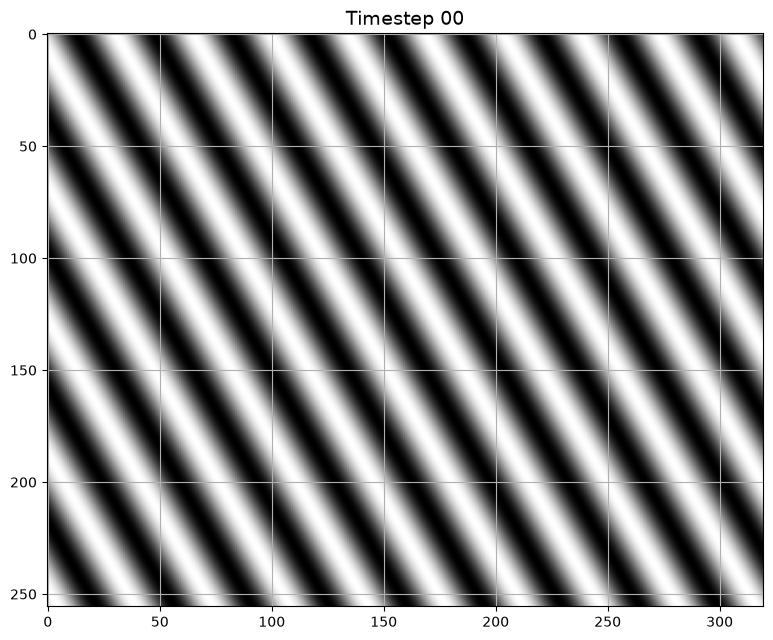

In [5]:
plot_images = [img.cpu().numpy() for img in wave_image_sequence]
show_image_list(list_images=plot_images,
                list_titles=[f"Timestep {t:02d}" for t in timesteps],
                list_cmaps=["gray" for t in timesteps],
                figsize=(17,6.5),
                num_cols=5,
                title_fontsize=14)

In [6]:
wave = PlaneWave2D(
    wavelength=30,
    angle=23,
    amplitude=10,
    phase=0,
    period=350, 
    seed=42,
    wl_tol=0.2,
    angle_noise=20,
    phase_noise=3.14/12,
    n_waves=5,
    mask=PerlinNoise(
        seed=42,
        angle=20,
        velocity=0.05,
        clip=(0.3, 0.6),
        octaves=7,
        gauss_ksize=0
    )
)

timesteps = np.arange(0, 10)
image_shape = (256, 320)
resolution_px_per_km=2
resolution_seconds_per_time_step=60

wave_image_sequence = []
for t in timesteps:
    wave.generate(wave.amplitude, 
                img_shape=image_shape,
                timestep=t,
                resolution_px_per_km=resolution_px_per_km,
                resolution_seconds_per_time_step=resolution_seconds_per_time_step)
    wave_image_sequence.append(wave._wave_image)

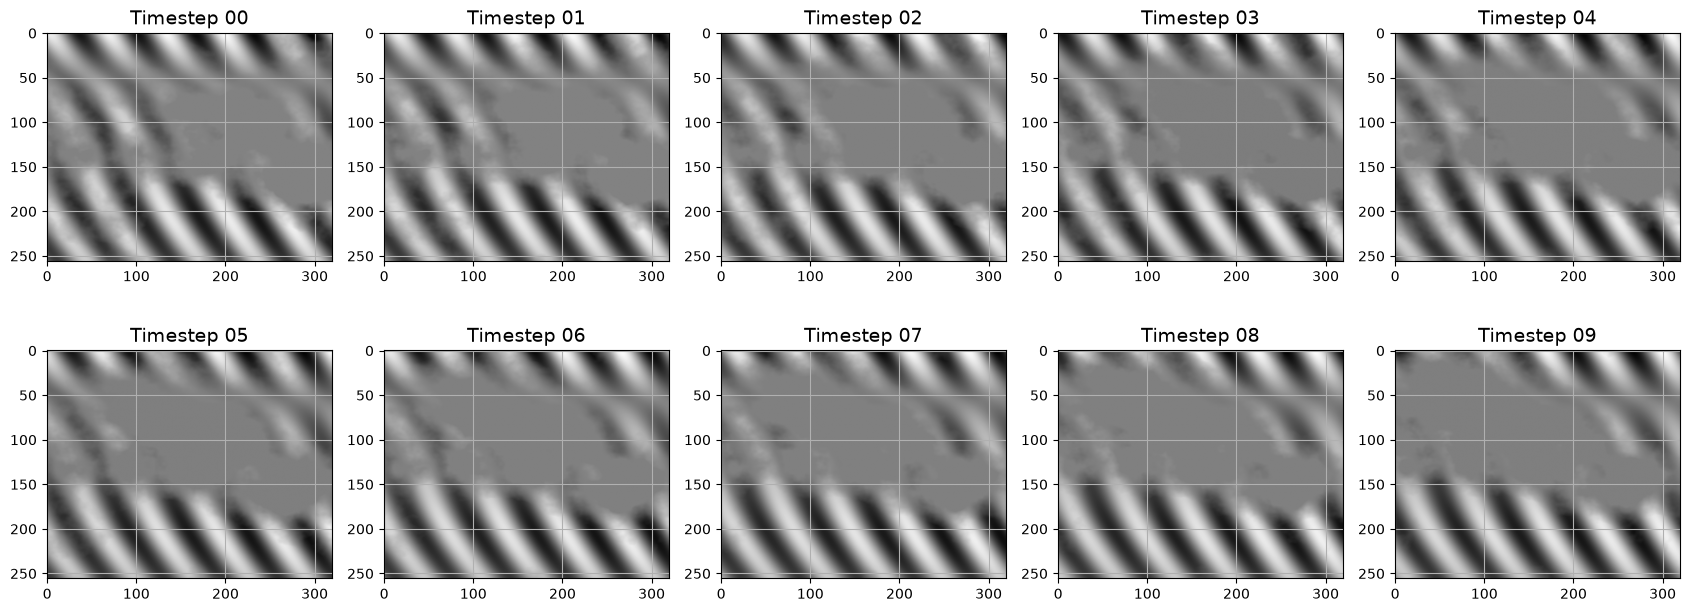

In [7]:
plot_images = [img.cpu().numpy() for img in wave_image_sequence]
show_image_list(list_images=plot_images,
                list_titles=[f"Timestep {t:02d}" for t in timesteps],
                list_cmaps=["gray" for t in timesteps],
                figsize=(17,6.5),
                num_cols=5,
                title_fontsize=14)

### Test superposition of multiple waves

In [8]:
waves = [
    PlaneWave2D(
        wavelength=30,
        angle=23,
        amplitude=10,
        phase=0,
        period=350, 
        seed=12566,
        wl_tol=0.2,
        angle_noise=20,
        phase_noise=3.14/12,
        n_waves=3,
        mask=PerlinNoise(
            seed=516165,
            angle=20,
            velocity=0.05,
            clip=(0.1, 0.4),
            octaves=7,
            gauss_ksize=0
        )
    ),
    PlaneWave2D(
        wavelength=170,
        angle=87,
        amplitude=30,
        phase=0,
        period=1200, 
        seed=116,
        wl_tol=0.2,
        angle_noise=5,
        phase_noise=3.14/12,
        n_waves=3,
        mask=PerlinNoise(
            seed=6165,
            angle=51,
            velocity=0.01,
            clip=(0.1, 0.6),
            octaves=3,
           gauss_ksize=0
        )
    ),
    PlaneWave2D(
        wavelength=17,
        angle=57,
        amplitude=7,
        phase=0,
        period=300, 
        seed=125616,
        wl_tol=0.2,
        angle_noise=6,
        phase_noise=3.14/12,
        n_waves=4,
        mask=PerlinNoise(
            seed=5165,
            angle=30,
            velocity=0.05,
            clip=(0.4, 0.6),
            octaves=7,
            gauss_ksize=0
        )
    ),
]

timesteps = np.arange(0, 10)
wave_image_sequence = []
for t in timesteps:
    # migration to pytorch
    # wave_image_superposition = np.zeros(image_shape, dtype = np.float32)
    wave_image_superposition = torch.zeros(image_shape, dtype = torch.float32)
    for wave in waves:
        wave.generate(wave.amplitude, 
                    img_shape=image_shape,
                    timestep=t,
                    resolution_px_per_km=resolution_px_per_km,
                    resolution_seconds_per_time_step=resolution_seconds_per_time_step)
        wave_image_superposition += wave._wave_image
    wave_image_sequence.append(wave_image_superposition)



#### Plot image sequence of superimposed waves

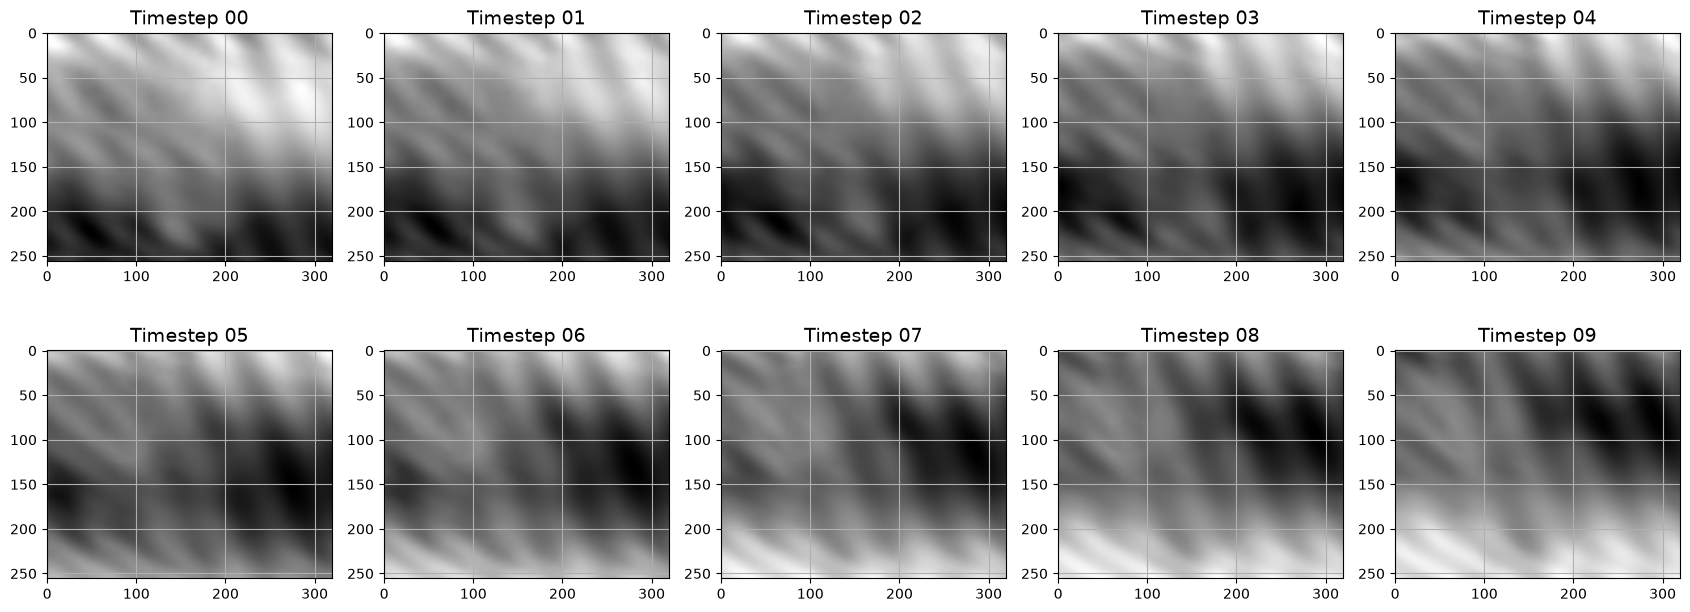

In [9]:
plot_images = [img.cpu().numpy() for img in wave_image_sequence]
show_image_list(list_images=plot_images,
                list_titles=[f"Timestep {t:02d}" for t in timesteps],
                list_cmaps=["gray" for t in timesteps],
                figsize=(17,6.5),
                num_cols=5,
                title_fontsize=14)

### Add simple sensor noise

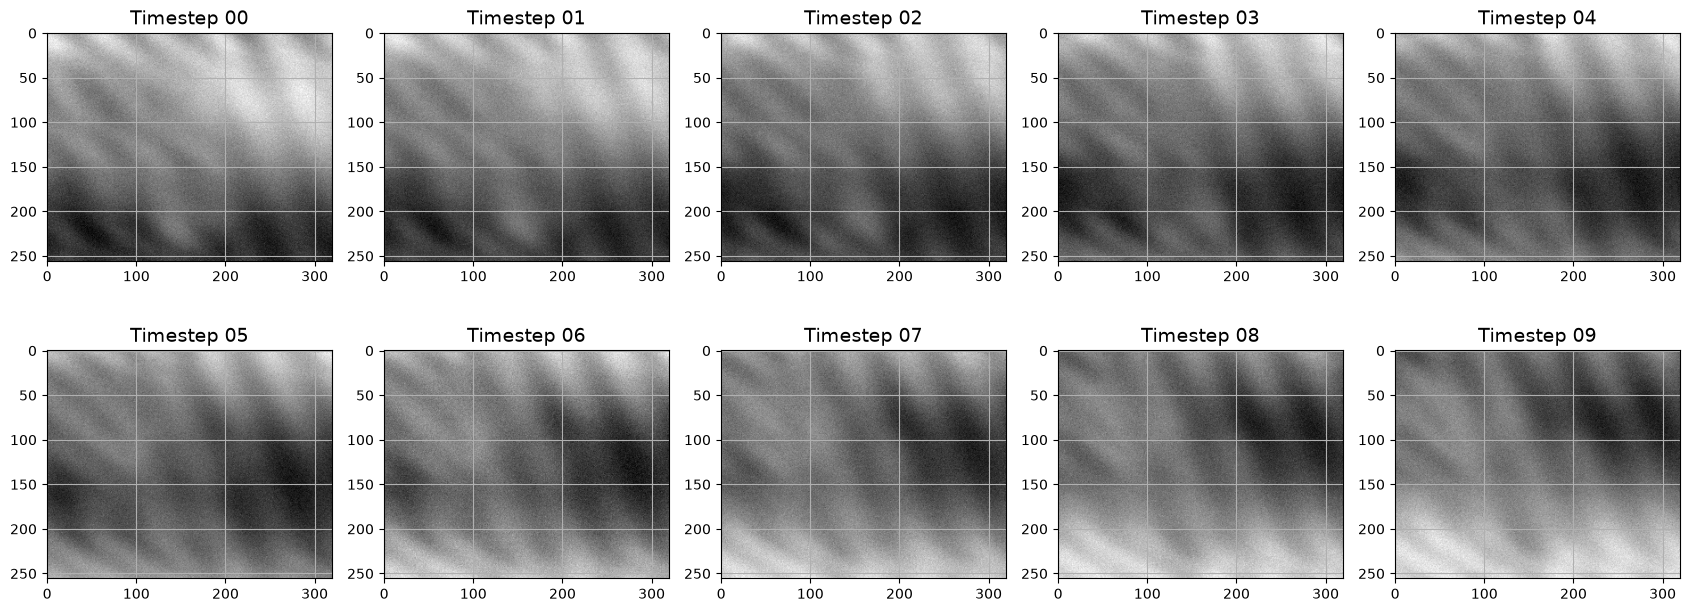

In [10]:

# migration to pytorch
'''
from src.utils.utility import gaussian_noise
noise_sd=4
sensor_noise_seed=5161
rng = np.random.default_rng(sensor_noise_seed)

wave_image_sequence_with_noise = [wave_image + gaussian_noise(image_shape, sd=noise_sd, rng=rng) for wave_image in wave_image_sequence]'''
noise_sd = 4
sensor_noise_seed = 5161
gen = torch.Generator(device=wave_image_sequence[0].device).manual_seed(sensor_noise_seed)

wave_image_sequence_with_noise = [wave_img + torch.randn(wave_img.shape, generator=gen, dtype=wave_img.dtype, device=wave_img.device) * noise_sd for wave_img in wave_image_sequence]

plot_images = [img.cpu().numpy() for img in wave_image_sequence_with_noise]
show_image_list(list_images=plot_images,
                list_titles=[f"Timestep {t:02d}" for t in timesteps],
                list_cmaps=["gray" for t in timesteps],
                figsize=(17,6.5),
                num_cols=5,
                title_fontsize=14)

#### process as short video sequence with more timesteps
1. Generate image sequence
2. Add noise
3. Save images to disc
4. Use external tool (ffmpeg) to generate a video:

    e.g. "ffmpeg -i output/wave_sequence_test_v1/%03d.png -r 20 output/wave_sequence_test_v1.mp4"
    
    -r 20 is 20 frames per second, %03d is the wildcard for zero-trailing numbers (000, 001, ...)

In [11]:
import cv2
from src.utils.utility import gaussian_noise

outdir="output/"

timesteps=np.arange(0, 120)
resolution_seconds_per_time_step=2

# generate image sequence
wave_image_sequence = []
for t in timesteps:
    # migration to pytorch
    # wave_image_superposition = np.zeros(image_shape, dtype = np.float32)
    wave_image_superposition = torch.zeros(image_shape, dtype = torch.float32)
    for wave in waves:
        wave.generate(wave.amplitude, 
                    img_shape=image_shape,
                    timestep=t,
                    resolution_px_per_km=resolution_px_per_km,
                    resolution_seconds_per_time_step=resolution_seconds_per_time_step)
        wave_image_superposition += wave._wave_image
    wave_image_sequence.append(wave_image_superposition)

# add noise to sequence
# this is an example of using the gaussian_noise function so a conversion to numpy is needed
noise_sd=4
sensor_noise_seed=2414
rng = np.random.default_rng(sensor_noise_seed)
wave_image_sequence_with_noise = [wave_image.cpu().numpy() + gaussian_noise(image_shape, sd=noise_sd, rng=rng) for wave_image in wave_image_sequence]
'''noise_sd = 4
sensor_noise_seed = 5161
gen = torch.Generator(device=wave_image_sequence[0].device).manual_seed(sensor_noise_seed)

wave_image_sequence_with_noise = [wave_img + torch.randn(wave_img.shape, generator=gen, dtype=wave_img.dtype, device=wave_img.device) * noise_sd for wave_img in wave_image_sequence]'''


'noise_sd = 4\nsensor_noise_seed = 5161\ngen = torch.Generator(device=wave_image_sequence[0].device).manual_seed(sensor_noise_seed)\n\nwave_image_sequence_with_noise = [wave_img + torch.randn(wave_img.shape, generator=gen, dtype=wave_img.dtype, device=wave_img.device) * noise_sd for wave_img in wave_image_sequence]'

In [12]:
# convert to 8-bit (by adjusting the contrast, i.e. using the full 8-bit value range)

def adjust_contrast_of_float_img(img: np.ndarray):
    """Convert image values into (0, 1) range"""
    if not np.issubdtype(img.dtype, np.floating):
        raise ValueError(f"Image is not of floating-point type, but {img.dtype}")
    min_val, max_val = img.min(), img.max()
    return (img - min_val) / (max_val - min_val)

def convert_32bit_to_8bit(img: np.ndarray):
    img_0_1=adjust_contrast_of_float_img(img)
    img_0_255=img_0_1*255
    return img_0_255.astype(np.uint8)

wave_image_sequence_with_noise_8bit = [convert_32bit_to_8bit(wave_image) for wave_image in wave_image_sequence_with_noise]

# save images to disc
_ = [cv2.imwrite(filename=f"{outdir}{i:03d}.png", img=img) for i, img in enumerate(wave_image_sequence_with_noise_8bit)]


## Waves with realistic superposition and noise (parameters taken from the airglow-parameter-extraction repo)

Welle 1: wavelength=162.9 km, angle=344.7°, Amplitude=37.8, period=1288 s
Welle 2: wavelength=17.8 km, angle=223.3°, Amplitude=3.6, period=344 s
Welle 3: wavelength=22.6 km, angle=211.7°, Amplitude=8.2, period=153 s


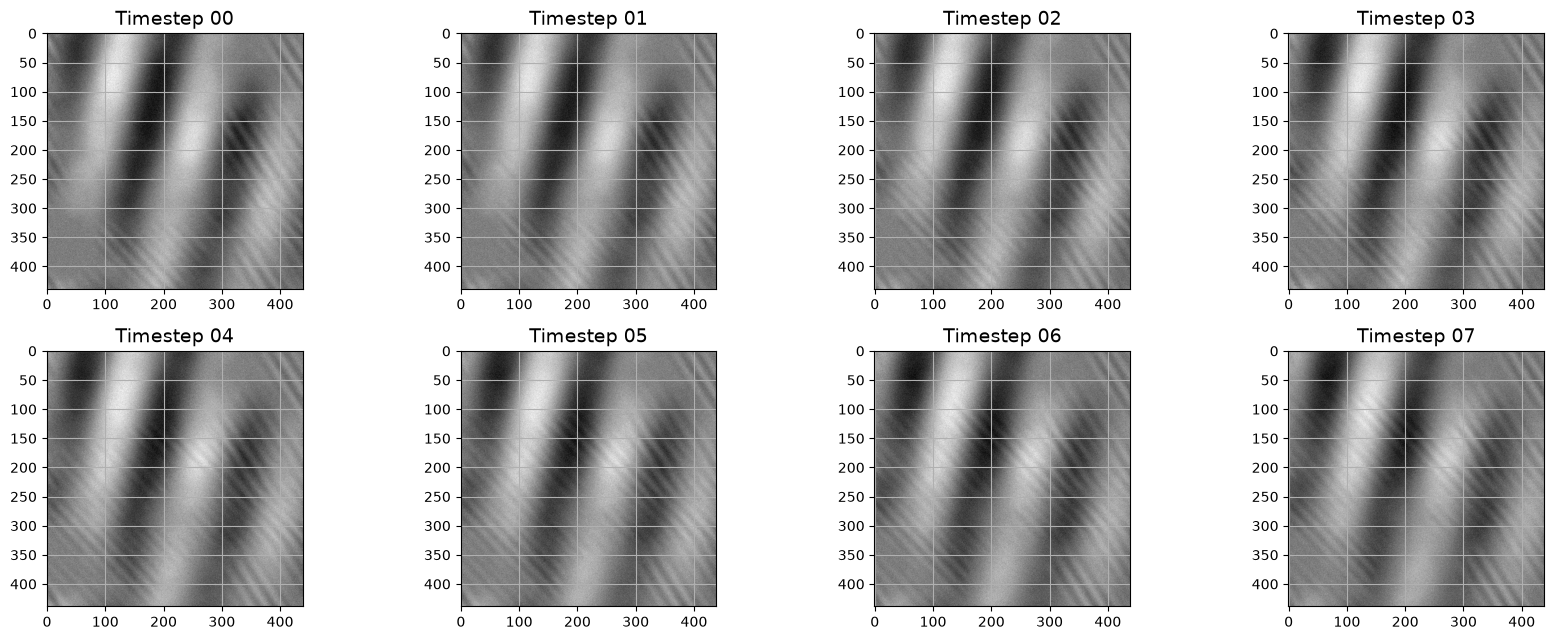

In [19]:
# These values are taken from the original generate_supervised_hdf5 script: Physical bounds for waves
SWELL = dict(wl=(80, 180), amp=(15, 40), per=(600, 1800), noise=dict(clip_lo=(0.05, 0.15), clip_hi=(0.85, 0.95), octaves=[3], vel=(0.005, 0.02), angle=(15, 90)))
CHOP  = dict(wl=(12, 45),  amp=(3, 12),  per=(150, 500), noise=dict(clip_lo=(0.3, 0.6),   clip_hi=(0.6, 0.8),  octaves=[0, 3, 7], vel=(0.04, 0.12), angle=(20, 90)))

def sample_wave(kind):
    return PlaneWave2D(
        wavelength=float(np.random.uniform(*kind["wl"])), # km
        angle=float(np.random.uniform(0, 360)), # geografisch (0 = Nord)
        amplitude=float(np.random.uniform(*kind["amp"])),
        phase=float(np.random.uniform(0, 2 * np.pi)), # Radiant
        period=float(np.random.uniform(*kind["per"])),
        seed=int(np.random.randint(0, 1_000_000)),
        wl_tol=0.2,
        angle_noise=float(np.random.uniform(1, 7)),
        phase_noise=np.pi / 12,
        n_waves=int(np.random.randint(3, 8)),
        mask = PerlinNoise(
            seed=int(np.random.randint(1, 1_000_000)),
            angle = float(np.random.uniform(*kind["noise"]["angle"])),
            velocity = float(np.random.uniform(*kind["noise"]["vel"])),
            clip = (float(np.random.uniform(*kind["noise"]["clip_lo"])),
                    float(np.random.uniform(*kind["noise"]["clip_hi"]))),
             octaves=int(np.random.randint(3, 8)), # currently same for all the waves
            gauss_ksize = 0)
        # mask = None
    )

# 1 swell + 2 chops
waves = [sample_wave(SWELL), sample_wave(CHOP), sample_wave(CHOP)]
for i, w in enumerate(waves):
    print(f"Welle {i+1}: wavelength={w.wavelength:.1f} km, angle={w.angle:.1f}°, Amplitude={w.amplitude:.1f}, period={w.period:.0f} s")

global_params = {
    "timesteps": np.arange(0, 8),
    "image_shape": (439, 439),
    "resolution_px_per_km": 1, # with resolution 1 the frames look a bit too perfect
    "resolution_seconds_per_time_step": 30,
    "sensor_noise": {
        "type": "gaussian",
        "sd": 4,
        "seed": int(np.random.randint(0, 1_000_000)),
    },
}

image_shape = tuple(global_params["image_shape"])
noise = global_params["sensor_noise"]

wave_image_sequence = []
for t in global_params["timesteps"]:
    superposition = torch.zeros(image_shape, dtype=torch.float32)
    for wave in waves:
        wave.generate(wave.amplitude,
                      img_shape=image_shape,
                      timestep=int(t),
                      resolution_px_per_km=global_params["resolution_px_per_km"],
                      resolution_seconds_per_time_step=global_params["resolution_seconds_per_time_step"])
        superposition += wave._wave_image.float()
    # currently no further noise added on the superposition. This is the place where you could add it.
    # gaussian noise as in the original generate_supervised_hdf5 script, but now using torch instead of numpy
    g = torch.Generator().manual_seed(noise["seed"] + int(t))
    superposition += torch.randn(image_shape, generator=g) * noise["sd"]

    wave_image_sequence.append(superposition)

stacked = torch.stack(wave_image_sequence)

# standardizing on the whole sequence after noise, as in the repo
stacked = (stacked - stacked.mean()) / (stacked.std() + 1e-8)

plot_images = [img.cpu().numpy() for img in stacked]

show_image_list(list_images=plot_images,
                list_titles=[f"Timestep {int(t):02d}" for t in global_params["timesteps"]],
                list_cmaps=["gray"] * len(plot_images),
                figsize=(17, 6.5),
                num_cols=4,
                title_fontsize=14)